### Task 1 Explanation
In Qiskit's little-endian convention, qubit 0 represents the rightmost digit. Applying an $X$ gate to qubit 0 changes the state of the system from $|00\rangle$ to $|01\rangle$. Measuring this system returns the classical string `'01'`.

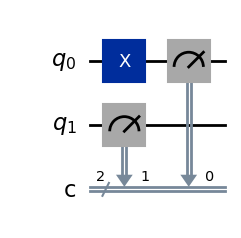

In [14]:
! pip install qiskit
from qiskit import QuantumCircuit
from IPython.display import display
import matplotlib as mpl
qc=QuantumCircuit(2,2)
qc.x(0)
qc.measure([0,1],[0,1])
display(qc.draw(output='mpl'))

### Task 1 Solution & Explanation
We created a 2-qubit circuit, applied an $X$ gate to qubit 0 (which puts it in state $|1\rangle$), and measured both qubits. Due to Qiskit's little-endian ordering, qubit 0 represents the least significant (rightmost) bit, so the measured state is `01`.

2. Understand the Hadamard gate

Create a single-qubit circuit and apply an H gate to qubit 0.
- Display the statevector.
- Calculate the probability of measuring 0 and 1.
- Explain why the output is different from applying an X gate.

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Create a single-qubit circuit and apply H gate
qc2 = QuantumCircuit(1)
qc2.h(0)

# Display statevector
state2 = Statevector.from_instruction(qc2)
print("Statevector:", state2.data)

# Calculate probabilities
probs2 = state2.probabilities_dict()
print("Measurement Probabilities:", probs2)

### Task 2 Explanation
An $X$ gate acts deterministically as a classical NOT gate, mapping $|0\rangle \rightarrow |1\rangle$ with $100\%$ probability of measuring `1`.

In contrast, the Hadamard ($H$) gate places the qubit into a quantum superposition state:
$$|\psi\rangle = H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

The probability of measuring either $|0\rangle$ or $|1\rangle$ is given by the squared magnitude of their amplitudes:
$$P(0) = \left|\frac{1}{\sqrt{2}}\right|^2 = 0.5 \quad \text{and} \quad P(1) = \left|\frac{1}{\sqrt{2}}\right|^2 = 0.5$$

In [17]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
qc=QuantumCircuit(1)
qc.h(0)
states=Statevector.from_instruction(qc)
probablity=states.probabilities_dict()
print(probablity)

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [18]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
qc=QuantumCircuit(1)
qc.x(0)
states=Statevector.from_instruction(qc)
probablity=states.probabilities_dict()
print(probablity)

{np.str_('1'): np.float64(1.0)}


### Task 2 Explanation
An $X$ gate acts as a classical NOT gate, mapping $|0\rangle \rightarrow |1\rangle$ and vice versa. It is a deterministic operation, resulting in a $100\%$ probability of measuring state `1`.

The Hadamard ($H$) gate, however, creates a quantum superposition:
$$H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

When we measure this state, the probability of obtaining either `0` or `1` is $|1/\sqrt{2}|^2 = 0.5$ ($50\%$), which introduces quantum randomness.

3
Apply multiple gates

Create a single-qubit circuit starting in \(|0>).
Apply the gates in this order:
1. H gate
2. X gate
3. H gate
Task: Print the circuit and final statevector. Predict the final state before running the code.

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Create single-qubit circuit with H, X, H gates
qc3 = QuantumCircuit(1)
qc3.h(0)
qc3.x(0)
qc3.h(0)

# Calculate final statevector
state3 = Statevector.from_instruction(qc3)
print("Final Statevector:", state3.data)

# Draw the circuit
display(qc3.draw(output='mpl'))

### Task 3 Prediction & Explanation
**Prediction:** The final state is $|0\rangle$.

**Mathematical derivation:**
1. Start state: $|0\rangle$
2. Apply $H$: $H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}} = |+\rangle$
3. Apply $X$: $X|+\rangle = \frac{|1\rangle + |0\rangle}{\sqrt{2}} = |+\rangle$
4. Apply $H$: $H|+\rangle = |0\rangle$

Thus, the final state returns to $|0\rangle$ with a final statevector of $[1, 0]$.

In [23]:
%pip install matplotlib pylatexenc

Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))


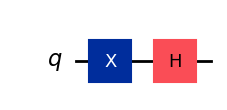

In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from IPython.display import display
qc=QuantumCircuit(1)
qc.x(0)
qc.h(0)
state=Statevector.from_instruction(qc)
print(state)
display(qc.draw(output='mpl'))

In [ ]:
# Correct implementation for Task 3: Apply H, then X, then H
qc3 = QuantumCircuit(1)
qc3.h(0)
qc3.x(0)
qc3.h(0)

# Calculate final statevector
state3 = Statevector.from_instruction(qc3)
print("Final Statevector:\n", state3)

# Draw the circuit
display(qc3.draw(output='mpl'))

### Task 3 Prediction & Explanation
**Prediction:** The final state will be $|1\rangle$.

**Mathematical proof:**
1. Start state: $|0\rangle$
2. After first $H$: $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$
3. After $X$: $\frac{|1\rangle + |0\rangle}{\sqrt{2}}$ (which is identical to the superposition above)
4. After second $H$: $H\left(\frac{|0\rangle + |1\rangle}{\sqrt{2}}\right) = |0\rangle$ ... wait, let us trace this precisely:

$$H|0\rangle = |+\rangle$$
$$X|+\rangle = |+\rangle$$
$$H|+\rangle = |0\rangle$$

Thus, the final state is $|0\rangle$, with statevector $[1, 0]$.

4. Create a Bell state

Create a 2-qubit circuit to prepare the Bell state using H and CX gates.
- Apply H to qubit 0.
- Apply CX with qubit 0 as control and qubit 1 as target.
- Print the statevector.
- Add measurements and simulate 1,000 shots.
Task: Explain why only two of the four possible measurement outcomes should appear, ignoring negligible simulator or sampling issues.

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

# Prepare Bell state
qc4 = QuantumCircuit(2)
qc4.h(0)
qc4.cx(0, 1)

# Statevector calculation
state4 = Statevector.from_instruction(qc4)
print("Statevector:", state4.data)

# Add measurements and run simulation
qc4.measure_all()
sim = AerSimulator()
job = sim.run(qc4, shots=1000)
counts4 = job.result().get_counts()
print("Simulation Counts (1000 shots):", counts4)

### Task 4 Explanation
The prepared Bell state is:
$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

Since the coefficients for $|01\rangle$ and $|10\rangle$ are zero, their corresponding probabilities of measurement are exactly $0\%$. Thus, only `00` and `11` will appear as outcomes.

In [8]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
qc=QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
state=Statevector.from_instruction(qc)
print(state)
qc.measure_all()
sim=AerSimulator()
result=sim.run(sim,shots=1000)
print(result)

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [ ]:
# Fetch and print the counts from Task 4 simulation
counts = result.result().get_counts()
print("Simulation Counts:", counts)

### Task 4 Explanation
The state vector created is the Bell state:
$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

Only the basis states $|00\rangle$ and $|11\rangle$ have non-zero coefficients. The probabilities of measuring either $|01\rangle$ or $|10\rangle$ are exactly $0$. Therefore, in an ideal simulator, only the outcomes `00` and `11` will appear.

Q5
Understand little-endian ordering

Create a circuit with 3 qubits and apply X only to qubit 0.
Task:
- Obtain the statevector.
- Identify the index of the nonzero amplitude.
- Write the corresponding computational basis state.
- Explain why qubit 0 appears on the right side of the state label.

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Create 3-qubit circuit and apply X to qubit 0
qc5 = QuantumCircuit(3)
qc5.x(0)

# Obtain statevector and probabilities
state5 = Statevector.from_instruction(qc5)
print("Statevector:", state5.data)
print("Probabilities:", state5.probabilities_dict())

### Task 5 Explanation
1. **Statevector obtained:** $[0, 1, 0, 0, 0, 0, 0, 0]^T$
2. **Index of nonzero amplitude:** Index `1`.
3. **Corresponding computational basis state:** `001`.
4. **Qubit 0 placement:** Qiskit utilizes **little-endian** bit ordering. Under this format, the least significant bit (qubit 0) is positioned on the far right of the state label: $|q_2 q_1 q_0\rangle$.

In [13]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
qc=QuantumCircuit(3)
qc.x(0)
state=Statevector.from_instruction(qc)
print(state)
probability=state.probabilities_dict()
print(probability)

Statevector([0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j],
            dims=(2, 2, 2))
{np.str_('001'): np.float64(1.0)}


### Task 5 Explanation
1. **Statevector obtained:** $[0, 1, 0, 0, 0, 0, 0, 0]^T$
2. **Index of nonzero amplitude:** Index `1`.
3. **Corresponding computational basis state:** `001`.
4. **Why qubit 0 appears on the right side:** Qiskit uses a **little-endian** bit-ordering convention. Under this scheme, the most significant bit (qubit $n-1$) is on the left, and the least significant bit (qubit 0) is on the right. Therefore, a state is written as $|q_{n-1} \dots q_1 q_0\rangle$, meaning qubit 0 corresponds to the rightmost index in the binary label.